# 07 — The Awareness Gap

**The gap in existing work.** Studies that link search to air pollution ask one question — *do the two correlate?* — and answer with one number. That treats public attention as a fixed, linear, always-on response. A correlation cannot say:

- whether people react to the pollution level or to pollution being *unusual*;
- whether there is a level below which nobody looks;
- how quickly attention arrives after a spike, and how quickly it fades;
- whether attention wears out over a long polluted season;
- how often the air is bad and nobody searches at all.

**What this notebook does.** It measures each of those five things per city, using the composite attention index from the EDA (the first principal component of each city's search terms, in standard deviations). Together they form an **Awareness Gap scorecard**: a description of *when* search is a usable proxy for public awareness and when it is not.

Every estimate carries an interval that allows for autocorrelation. With three years of data several of them are wide, and the text says so where that matters.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import awareness as A, features as F, plots as P, stats as S
from aqs.config import CITIES, PROCESSED

pd.set_option("display.precision", 3)
P.use_theme()
long = F.load_long()

## 1. Level or surprise?

PM2.5 is split into the part the calendar predicts (a seasonal fit) and the part it does not (the residual). Attention is regressed on both at once. If people only followed the calendar — searching every January out of habit — the surprise component would have no effect.

In [2]:
pd.concat({c: A.level_vs_surprise(F.attention_pair(long, c)) for c in CITIES})

effect    low   high          p
bangkok   expected   0.750  0.519  0.982  2.057e-10
          surprise   0.665  0.369  0.960  1.023e-05
krakow    expected   1.107  0.838  1.375  5.969e-16
          surprise   0.463  0.208  0.719  3.784e-04
melbourne expected  -2.075 -4.573  0.422  1.034e-01
          surprise   0.267 -0.586  1.120  5.395e-01

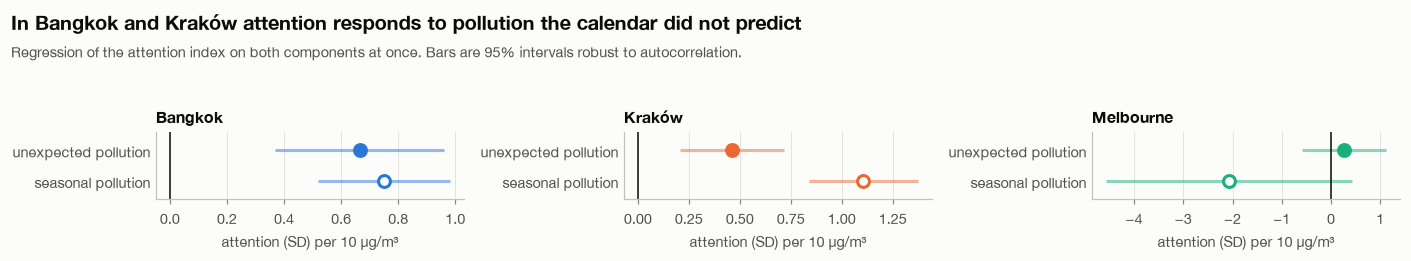

In [3]:
P.level_vs_surprise_plot(long);

**Reading it.** In Bangkok an unexpected 10 µg/m³ raises attention by about two-thirds of a standard deviation, nearly as much as the same amount of seasonal pollution. People there respond to the air, not only to the date. In Kraków both components matter, but seasonal pollution moves attention more than twice as much as a surprise does: Kraków's attention is partly a seasonal habit. In Melbourne neither is distinguishable from zero.

## 2. Is there a switch-on level?

A flat-then-rising line is fitted: attention stays at a base level until PM2.5 passes a threshold, then rises. The threshold is searched over the observed range and compared with a plain straight line.

In [4]:
pd.DataFrame({c: A.attention_threshold(F.attention_pair(long, c)) for c in CITIES}).T

,threshold,low,high,base,slope_per_10,aic_gain_vs_linear
bangkok,21.907,12.926,34.950,-0.485,0.993,1.817
krakow,8.035,7.664,18.149,-0.773,0.770,-2.008
melbourne,7.145,3.893,8.226,0.067,-1.612,1.218


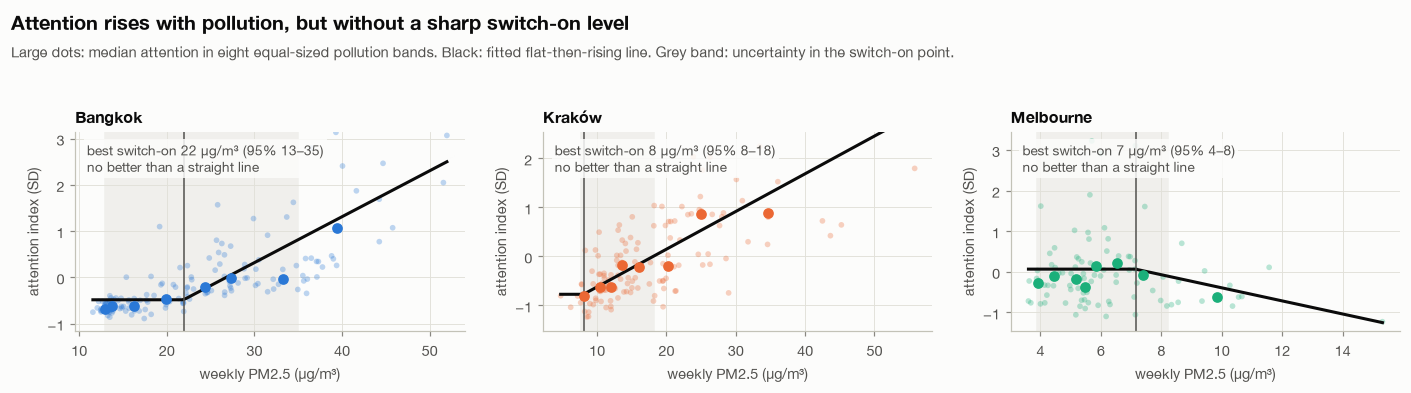

In [5]:
P.dose_response(long);

**Reading it.** This is a negative result. In no city does the threshold model fit meaningfully better than a straight line, and the intervals on the switch-on point are wide (13–35 µg/m³ in Bangkok). Bangkok's binned medians do look flat below about 20 µg/m³, but three years of weekly data cannot separate that from a steady rise. At weekly resolution, attention scales roughly in proportion to pollution.

## 3. How fast does attention arrive, and how long does it last?

An *episode* starts in a week when PM2.5 jumps at least two robust standard deviations above its seasonal expectation, after at least three calmer weeks. Each episode's pollution and attention are measured relative to the four weeks before it, then averaged.

In [6]:
pd.DataFrame({c: A.episode_response(F.attention_pair(long, c))["summary"] for c in CITIES}).T

,episodes,peak_week,peak_response,peak_low,peak_high,weeks_to_half
bangkok,6.0,1.0,0.973,-0.624,3.394,1.0
krakow,6.0,0.0,0.545,-0.431,1.895,1.0
melbourne,5.0,8.0,0.147,-0.084,0.460,NaN


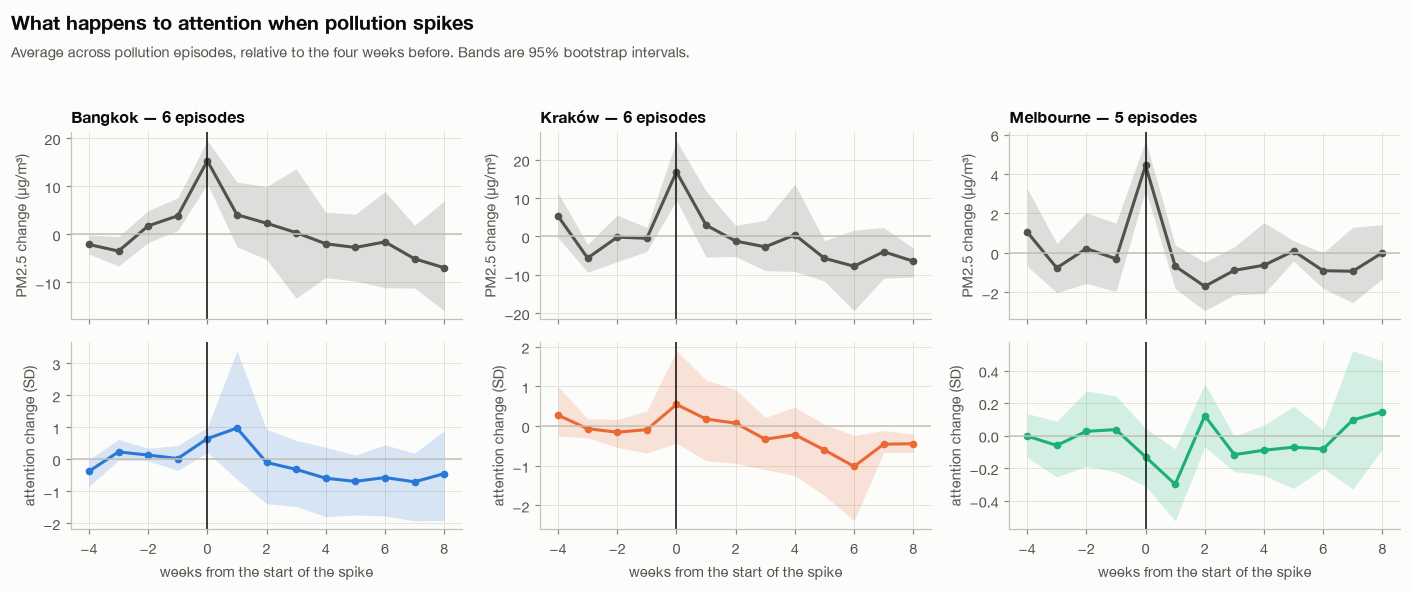

In [7]:
P.episode_curves(long);

**Reading it.** In Bangkok attention rises in the week of the spike (clearly above zero in week 0), peaks the week after, and is back to baseline by week 2. In Kraków the shape is similar — up in week 0, gone within a week or two — but with six episodes the band includes zero throughout. Melbourne shows no response.

Attention is immediate and short-lived: it tracks the spike itself and does not linger. With five or six episodes per city the size of the response is imprecise; the timing is the more reliable part.

## 4. Does attention wear out over a season?

Among each city's high-pollution weeks (the top third), attention is regressed on the pollution level and on how many high-pollution weeks the city has already had that season. A negative effect means the same pollution draws less attention later in the season: habituation. The estimate is repeated with each season left out in turn.

In [8]:
pd.DataFrame({c: A.habituation(F.attention_pair(long, c), c) for c in CITIES}).T

,high_weeks,effect_per_week,low,high,p,leave_one_season_min,leave_one_season_max
bangkok,50.0,0.070,0.034,0.106,1.567e-04,0.053,0.089
krakow,45.0,-0.051,-0.089,-0.013,8.214e-03,-0.124,-0.039
melbourne,32.0,-0.051,-0.238,0.136,5.934e-01,-0.077,0.001


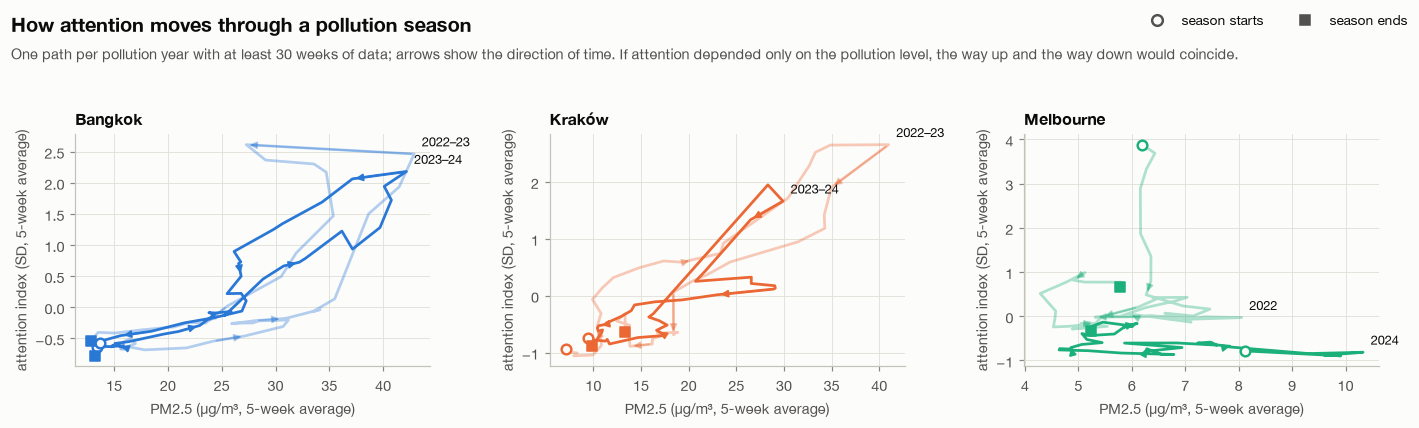

In [9]:
P.hysteresis(long);

**Reading it.** The two polluted cities move in opposite directions. In Kraków each additional high-pollution week already endured lowers attention by about 0.05 standard deviations at the same pollution level, and the sign holds whichever season is left out: Kraków habituates. In Bangkok the effect is positive and equally stable: attention builds as the season goes on.

A caution: "weeks into the season" is tied to the calendar, so this cannot be fully separated from anything else that changes through a season, such as media coverage or school terms. Three seasons per city is also few.

## 5. Silent pollution weeks

A week is *polluted* if its PM2.5 is in the top third for that city, and *silent* if attention that week is below the city's own median.

In [10]:
pd.DataFrame({c: A.silent_weeks(F.attention_pair(long, c), c)[1] for c in CITIES}).T

,high_weeks,silent_weeks,silent_share,low,high,silent_share_early,silent_share_late
bangkok,50.0,1.0,0.020,0.000,0.060,0.043,0.000
krakow,45.0,4.0,0.089,0.022,0.200,0.050,0.120
melbourne,32.0,16.0,0.500,0.188,0.906,0.562,0.438


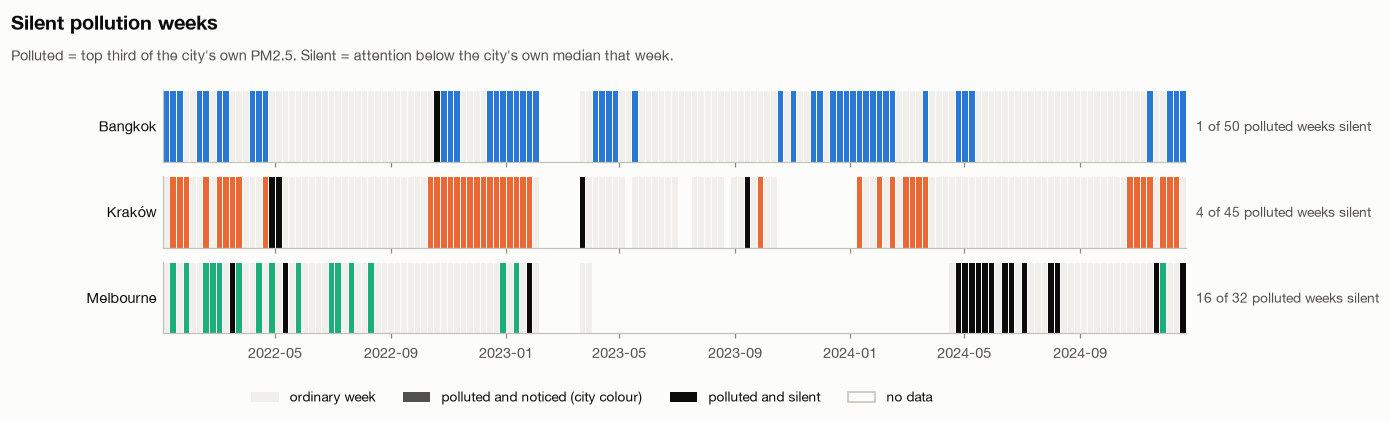

In [11]:
P.silent_strips(long);

**Reading it.** Bangkok has almost no silent weeks: when the air is bad, people search. Kraków has four, three of them in the later part of a season, which fits the habituation result but is too few to lean on. In Melbourne half of the relatively polluted weeks pass without elevated attention.

Melbourne's result needs its context. "Polluted" is relative to each city, and Melbourne's top third starts at about 6 µg/m³, well under the WHO guideline of 15. Those weeks are silent because the air is not bad enough to notice. Search is uninformative there because there is little to be informed about.

## The scorecard

In [12]:
card = A.scorecard(long)
card.to_csv(PROCESSED / "awareness_scorecard.csv")
card.T.round(2)

city,bangkok,krakow,melbourne
surprise_effect,0.66,0.46,0.27
surprise_p,0.00,0.00,0.54
expected_effect,0.75,1.11,-2.08
expected_p,0.00,0.00,0.10
threshold,21.91,8.04,7.15
threshold_low,12.93,7.66,3.89
threshold_high,34.95,18.15,8.23
threshold_aic_gain,1.82,-2.01,1.22
episodes,6.00,6.00,5.00
peak_week,1.00,0.00,8.00


## What the Awareness Gap says

| | Bangkok | Kraków | Melbourne |
|---|---|---|---|
| Responds to unexpected pollution | Yes, strongly | Yes, less than to seasonal | No |
| Sharp switch-on level | Not detectable | Not detectable | Not detectable |
| Timing of response | Same week, gone in two | Same week, gone in two (imprecise) | None |
| Over a season | Attention builds | Attention wears out | No pattern |
| Silent polluted weeks | 2% | 9% | 50% (low absolute pollution) |
| **Search as an awareness proxy** | **Reliable** | **Usable, weakens late in the season** | **Not informative** |

Search is a good proxy for public awareness where pollution is severe and variable, a weakening one where it is a long seasonal fact of life, and no proxy at all where the air is clean. A single correlation coefficient hides all three.